# 04. Анализ удовлетворенности клиентов (Reviews)

**Цель:** Оценить, как оценки клиентов (CSAT) влияют на их возврат. Это поможет маркетингу понять, насколько критично качество сервиса для удержания (Retention).

**Метод:** Анализ распределения оценок из таблицы `order_reviews` и их корреляция с повторными покупками.

,review_score,total_reviews,pct
0,1,11424,11.5
1,2,3151,3.2
2,3,8179,8.2
3,4,19142,19.3
4,5,57328,57.8


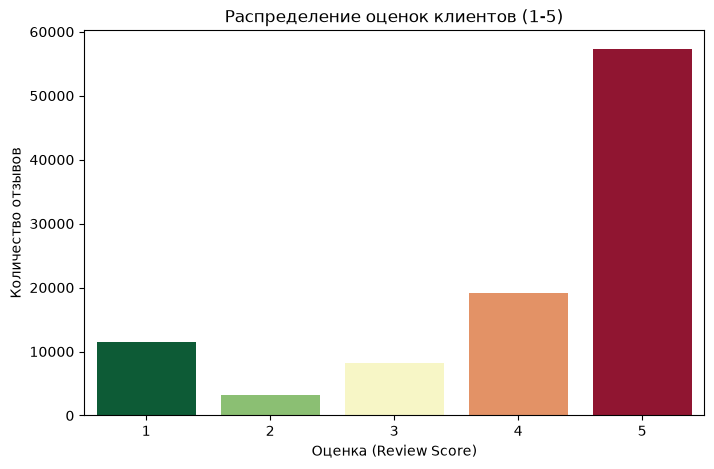

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

con = duckdb.connect()
con.execute("CREATE OR REPLACE VIEW orders AS SELECT * FROM read_csv_auto('../data/raw/olist_orders_dataset.csv')")
con.execute("CREATE OR REPLACE VIEW reviews AS SELECT * FROM read_csv_auto('../data/raw/olist_order_reviews_dataset.csv')")

# Распределение оценок
review_query = """
SELECT 
    review_score,
    COUNT(*) AS total_reviews,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM reviews), 1) AS pct
FROM reviews
GROUP BY 1
ORDER BY 1
"""
df_reviews = con.execute(review_query).df()
display(df_reviews)

# Визуализация
plt.figure(figsize=(8, 5))
sns.barplot(data=df_reviews, x='review_score', y='total_reviews', hue='review_score', palette='RdYlGn_r', legend=False)
plt.title('Распределение оценок клиентов (1-5)')
plt.xlabel('Оценка (Review Score)')
plt.ylabel('Количество отзывов')
plt.show()

### Вывод по удовлетворенности клиентов (CSAT)

- 77,1% отзывов имеют оценку 4 или 5. Это говорит о высокой оценке завершённого опыта покупки, но само по себе не доказывает лояльность или готовность к повторной покупке.
- 14,7% отзывов имеют оценку 1 или 2. Это приоритетная группа для отдельной проверки: нужно сравнить повторные покупки, причины негатива и типы проблем с доставкой.
- Следующим шагом можно протестировать триггерную коммуникацию для клиентов с оценкой 1–2: контакт службы поддержки, объяснение решения проблемы и персональная компенсация. Эффект такой механики нужно оценивать через A/B-тест.


### Почему высокие оценки не гарантируют повторную покупку?

В данных наблюдается сочетание высокой доли оценок 4–5 и низкой доли повторных покупок в первые месяцы. Это описательное наблюдение, а не доказательство причинной связи.

Возможные объяснения, которые стоит проверить:

1. В окне наблюдения может не хватать времени для следующей покупки.
2. На повторную покупку могут влиять категории товаров и частота потребности в них.
3. Отзыв отражает опыт конкретного заказа, а не всю ценность платформы для клиента.

Для идентификации повторных покупателей в датасете используется `customer_unique_id`; `customer_id` относится к отдельному заказу и может меняться.

### Гипотеза для следующего шага

Проверить, увеличивает ли персональная post-purchase коммуникация долю повторных покупок в течение 30–90 дней. Для проверки потребуется эксперимент с контрольной группой.
